### EDA
##### Author: Daniel
##### Last updated: 16/10/2026

### Exploration of:
#### - dailyActivity_merged.csv
#### - dailySteps_merged.csv
#### - hourlySteps_merged.csv
#### - minuteStepsNarrow_merged.csv

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Works when the kernel starts in the repository root or a notebook subfolder.
locations = [Path.cwd() / "datafolder", Path.cwd().parent / "datafolder"]
data_path = next((folder for folder in locations if (folder / "dailyActivity_merged.csv").is_file()), None)
if data_path is None:
    raise FileNotFoundError("Cannot find datafolder. Start Jupyter from the repository or its notebook subfolder.")

data_activity = pd.read_csv(data_path / "dailyActivity_merged.csv")
data_daily_steps = pd.read_csv(data_path / "dailySteps_merged.csv")
data_hourly = pd.read_csv(data_path / "hourlySteps_merged.csv")
data_minute = pd.read_csv(data_path / "minuteStepsNarrow_merged.csv")
print("Loaded four datasets from", data_path)

Loaded four datasets from c:\Users\dgann\Documents\DS2\DATA2007-Fitbit-Dashboard-Group\datafolder


### dailyActivity_merged.csv

##### Initial thoughts:
- Daily steps, calories and activity intensity.
- Useful for overall activity patterns.

In [2]:
print(data_activity.head())
print("Rows:", len(data_activity), "Participants:", data_activity.Id.nunique())
print("Duplicates:", data_activity.duplicated().sum())
print("Missing values:", data_activity.isna().sum().sum())
print(data_activity[["TotalSteps", "Calories", "SedentaryMinutes"]].describe().round(1))

           Id ActivityDate  TotalSteps  TotalDistance  TrackerDistance  \
0  1503960366    4/12/2016       13162           8.50             8.50   
1  1503960366    4/13/2016       10735           6.97             6.97   
2  1503960366    4/14/2016       10460           6.74             6.74   
3  1503960366    4/15/2016        9762           6.28             6.28   
4  1503960366    4/16/2016       12669           8.16             8.16   

   LoggedActivitiesDistance  VeryActiveDistance  ModeratelyActiveDistance  \
0                       0.0                1.88                      0.55   
1                       0.0                1.57                      0.69   
2                       0.0                2.44                      0.40   
3                       0.0                2.14                      1.26   
4                       0.0                2.71                      0.41   

   LightActiveDistance  SedentaryActiveDistance  VeryActiveMinutes  \
0                 6.06

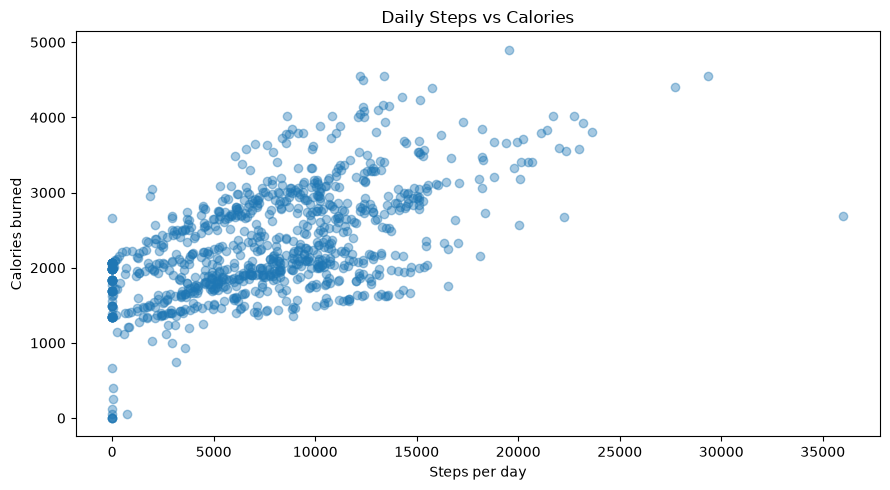

Correlation: 0.592


In [3]:
plt.figure(figsize=(9, 5))
plt.scatter(data_activity["TotalSteps"], data_activity["Calories"], alpha=0.4)
plt.title("Daily Steps vs Calories")
plt.xlabel("Steps per day")
plt.ylabel("Calories burned")
plt.tight_layout()
plt.show()
print("Correlation:", round(data_activity.TotalSteps.corr(data_activity.Calories), 3))

##### Observations:
- Steps and calories have a moderate positive correlation (~0.59).
- Steps alone do not explain calorie expenditure.

VeryActiveMinutes        21.2
FairlyActiveMinutes      13.6
LightlyActiveMinutes    192.8
SedentaryMinutes        991.2
dtype: float64


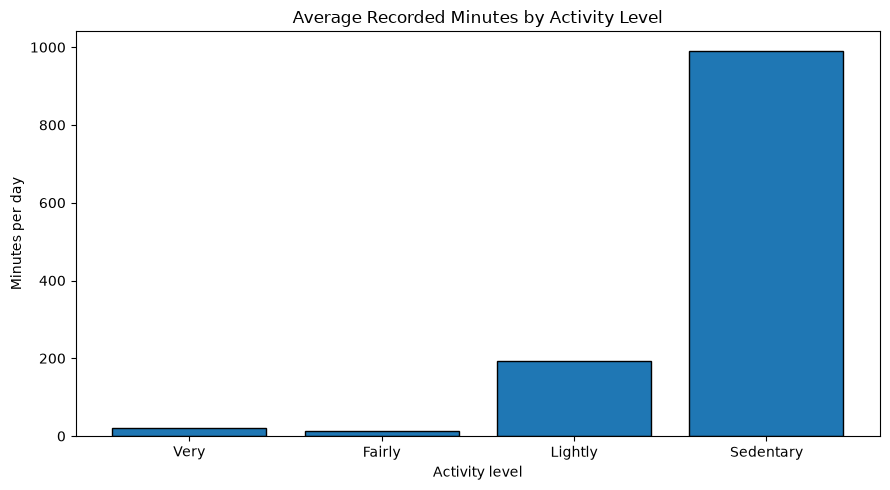

In [4]:
columns = ["VeryActiveMinutes", "FairlyActiveMinutes", "LightlyActiveMinutes", "SedentaryMinutes"]
means = data_activity[columns].mean()
print(means.round(1))
plt.figure(figsize=(9, 5))
plt.bar(["Very", "Fairly", "Lightly", "Sedentary"], means.values, edgecolor="black")
plt.title("Average Recorded Minutes by Activity Level")
plt.xlabel("Activity level")
plt.ylabel("Minutes per day")
plt.tight_layout()
plt.show()

##### Observations:
- Sedentary minutes dominate the recorded time.
- These minutes may include sleep or device non-wear.

### dailySteps_merged.csv

##### Initial thoughts:
- Daily step totals can be compared between participants.
- Check for overlap with dailyActivity.

Rows: 940 Participants: 33
Duplicates: 0
Missing values: 0


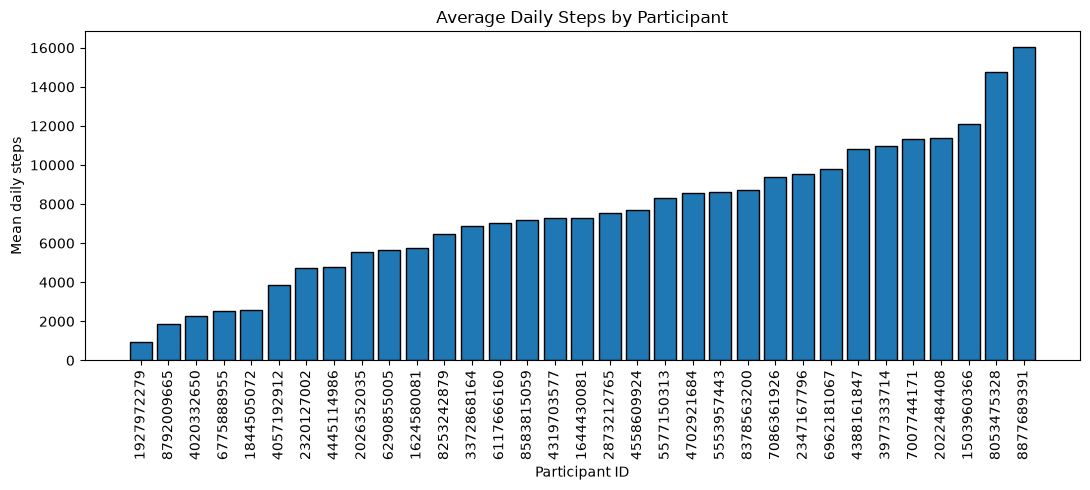

In [5]:
print("Rows:", len(data_daily_steps), "Participants:", data_daily_steps.Id.nunique())
print("Duplicates:", data_daily_steps.duplicated().sum())
print("Missing values:", data_daily_steps.isna().sum().sum())

averages = data_daily_steps.groupby("Id").StepTotal.mean().sort_values()
plt.figure(figsize=(11, 5))
plt.bar(averages.index.astype(str), averages.values, edgecolor="black")
plt.title("Average Daily Steps by Participant")
plt.xlabel("Participant ID")
plt.ylabel("Mean daily steps")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

##### Observations:
- Mean daily steps vary substantially between participants.
- Comparing daily averages avoids simply favouring participants with more records.

In [6]:
steps = data_daily_steps.copy()
activity = data_activity.copy()
steps["ActivityDay"] = pd.to_datetime(steps["ActivityDay"], format="%m/%d/%Y")
activity["ActivityDate"] = pd.to_datetime(activity["ActivityDate"], format="%m/%d/%Y")
check = steps.merge(activity[["Id", "ActivityDate", "TotalSteps"]],
                    left_on=["Id", "ActivityDay"], right_on=["Id", "ActivityDate"], how="inner")
print("Matching dated records:", len(check))
print("Matching step values:", (check.StepTotal == check.TotalSteps).sum())

Matching dated records: 940
Matching step values: 940


##### Observation:
- All 940 matched daily step totals agree. The separate dailySteps data is redundant for the dashboard.

### hourlySteps_merged.csv

##### Initial thoughts:
- Hourly measurements show *when* activity occurs.

Rows: 22099 Participants: 33
Duplicates: 0
Missing values: 0


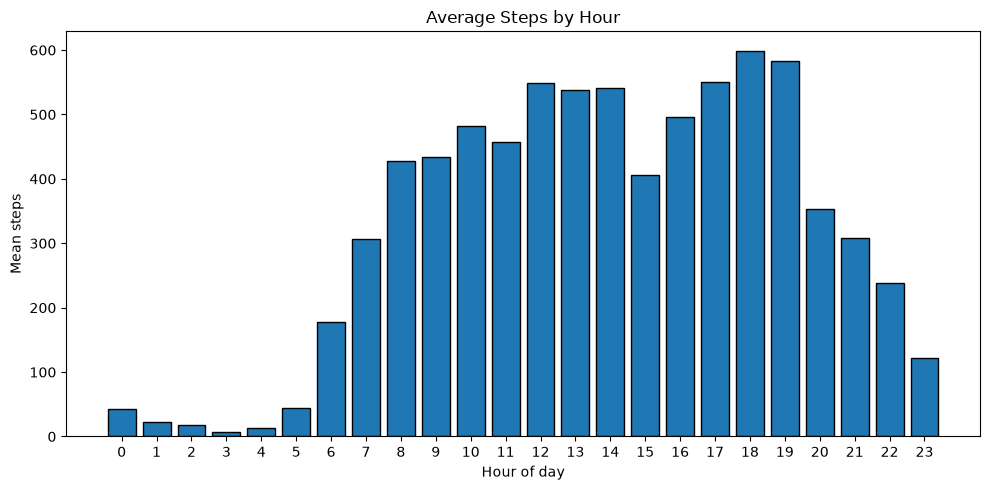

Peak hour: 18 Average steps: 599


In [7]:
print("Rows:", len(data_hourly), "Participants:", data_hourly.Id.nunique())
print("Duplicates:", data_hourly.duplicated().sum())
print("Missing values:", data_hourly.isna().sum().sum())

hourly = data_hourly.copy()
hourly["Hour"] = pd.to_datetime(hourly.ActivityHour, format="%m/%d/%Y %I:%M:%S %p").dt.hour
hour_means = hourly.groupby("Hour").StepTotal.mean()
plt.figure(figsize=(10, 5))
plt.bar(hour_means.index, hour_means.values, edgecolor="black")
plt.title("Average Steps by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Mean steps")
plt.xticks(range(24))
plt.tight_layout()
plt.show()
print("Peak hour:", hour_means.idxmax(), "Average steps:", round(hour_means.max()))

##### Observations:
- Average activity peaks at 18:00 (599 steps).
- Hourly patterns would make a useful dashboard chart.

### minuteStepsNarrow_merged.csv

##### Initial thoughts:
- Detailed minute-by-minute step data.
- Basic checks are sufficient here; hourly data is easier to interpret.

In [ ]:
print("Rows:", len(data_minute), "Participants:", data_minute.Id.nunique())
print("Duplicates:", data_minute.duplicated().sum())
print("Missing values:", data_minute.isna().sum().sum())
print("Zero-step minutes (%):", round(data_minute.Steps.eq(0).mean() * 100, 1))
print("Maximum steps per minute:", data_minute.Steps.max())

##### Observation:
- Most recorded minutes contain zero steps. These could include sleep or device non-wear.
- Aggregating minute data is more useful than plotting every minute.

### Overall findings
- **Daily activity:** useful steps, calories and activity intensity measures.
- **Daily steps:** duplicates the steps already in dailyActivity.
- **Hourly steps:** useful for time-of-day activity trends.
- **Minute steps:** detailed but not necessary for an initial dashboard.
- Interpret zero-step values cautiously.

In [8]:
activity_ids = set(data_activity["Id"])
daily_ids = set(data_daily_steps["Id"])
hourly_ids = set(data_hourly["Id"])
minute_ids = set(data_minute["Id"])

print("Daily activity participants:", len(activity_ids))
print("Daily steps participants:", len(daily_ids))
print("Hourly steps participants:", len(hourly_ids))
print("Minute steps participants:", len(minute_ids))

print("\nParticipants in all four datasets:")
print(len(activity_ids & daily_ids & hourly_ids & minute_ids))

print("\nAre all participant ID sets identical?")
print(activity_ids == daily_ids == hourly_ids == minute_ids)

Daily activity participants: 33
Daily steps participants: 33
Hourly steps participants: 33
Minute steps participants: 33

Participants in all four datasets:
33

Are all participant ID sets identical?
True
